# Domain-sequential streams: does T3's gain survive when domains arrive one after another?

**Question.** Every result so far comes from mixed streams (all domains shuffled together). In deployment, shifts arrive domain by domain, and Ramen's per-class queues carry one domain's entries into the next. Does the zero-shot-weighted active set (T3) still beat Ramen there, and what does the stream order do to Ramen itself?

**Hypothesis (pre-registered, `PREREGISTRATION.md`, written before any sequential run).** T3 − Ramen, domain-averaged, mean over seeds 0–4, is above the noise floor of the sequential stream on **all three** of ImageNet-C 5K, DomainNet and ImageNet-R/A/Sketch. Mixed-stream gains for reference: +0.62 / +0.24 / +0.59.

**Why this test.** It is the main untested deployment condition. Same images, configs and seeds as the mixed runs; only the order changes.

**Runs.**

| Name | Stream | What it is | Knows domain boundaries? |
|---|---|---|---|
| NoAdapt | — | CLIP zero-shot (stateless; the seed-0 mixed run, realigned) | — |
| Ramen | sequential | `cfg/<ds>/Ramen.yaml`, never reset | no |
| T3 | sequential | RamenActive `active_set: prob`, `temperature: 3`, never reset | no |
| Ramen-reset | single | Ramen reset at every domain start; same within-domain order | **yes (reference)** |
| Ramen (mixed), T3 (mixed) | mixed | the earlier runs, for comparison | no |

**Data and order.** ImageNet-C 5K: 15 corruptions × 5,000, standard order gaussian_noise → jpeg_compression. DomainNet: clipart → infograph → painting → quickdraw → real → sketch (596,006). ImageNet-R/A/Sketch: rendition → adversarial → sketch (88,389; 1,000-class head). One order per dataset (not varied).

**Seeds.** 0–4: the within-domain order and Ramen's selection randomness; the images are identical.

**How the runs were produced.** `bash run_queue.sh` (detached, one worker per GPU) runs `run_sequential.py <dataset> <seed> <run>`; the harness's new `tta_mode='sequential'` visits domains in order without resetting. Then `python sequential_analysis.py` → `results/sequential/*.csv`.

**What counts as a result.** Noise floor = 2 × (max − min) of sequential Ramen over seeds 0–4, per dataset (computed below). Secondary, with no pass/fail: the order effect on Ramen (sequential vs mixed, both minus NoAdapt), sequential Ramen vs Ramen-reset, and the adaptation lag after each domain switch (first 10 batches of a domain vs the rest).

**Amendment (before any sequential result).** Ramen's fp16 priorities freeze full queues after 65,520 samples, which in a sequential stream locks the memory on early domains. Ramen-fp32 and T3-fp32 (`priority_fp32: true`, eviction only) were added: DomainNet seeds 0–4, the other two seed 0 as a screen. On DomainNet, T3-fp32 − Ramen-fp32 is read with the same floor and rule as H1.

**Sections.** 1 Setup · 2 Data · 3 Sanity checks · 4 Primary result · 5 What the order does to Ramen · 6 Adaptation lag, memory composition, fp32 · 7 Per domain · 8 Interpretation · 9 Glossary

## 1. Setup

In [1]:
import os, sys
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '')
sys.path.insert(0, '..'); sys.path.insert(0, '../2026-10-25_stacking')
import numpy as np, pandas as pd
import stack, sequential_analysis as sa
pd.set_option('display.width', 220)
acc, g, lag, pdm = sa.load_csv('acc'), sa.load_csv(), sa.load_csv('lag'), sa.load_csv('per_domain')
FL = sa.floor(acc)
acc.groupby(['dataset', 'run']).seed.nunique().unstack()

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


run,NoAdapt,Ramen,Ramen (mixed),Ramen-fp32,Ramen-reset,T3,T3 (mixed),T3-fp32
dataset,,,,,,,,
DomainNet,5,5,5,5,5,5,5,5
ImageNetC5K,5,5,5,1,5,5,5,1
ImageNetVariants,5,5,5,1,5,5,5,1


## 2. The data the code ran on

In [2]:
stack.data_table(sa.DATASETS)

,ImageNet-C 5K,DomainNet,ImageNet-R/A/Sketch
model,clip_vitbase16,clip_vitbase32,clip_vitbase16
images,"75,000","596,006","88,389"
domains,15,6,3
images per domain,"5,000 each","48,833 to 175,327","7,500 to 50,889"
classes,997,345,1000
batches of 100,750,"5,961",884
NoAdapt correct,"20,468 of 75,000 (27.3%)","314,845 of 596,006 (52.8%)","44,942 of 88,389 (50.8%)"
Ramen correct (seed 0),"24,809 of 75,000 (33.1%)","324,966 of 596,006 (54.5%)","46,402 of 88,389 (52.5%)"
NoAdapt acc (domain-avg),27.29,55.37,46.36
"Ramen acc (domain-avg, seed 0)",33.08,56.8,47.86


In [3]:
pd.DataFrame({stack.LABEL[ds]: {'domain order': ' → '.join(pd.read_pickle(sa.path(ds, 0, 'sequential', 'Ramen')).domain.cat.categories),
                                 'Ramen (seq.) per seed': ', '.join(f'{a:.2f}' for a in acc[(acc.dataset == ds) & (acc.run == 'Ramen')].acc),
                                 'noise floor (2 x range)': round(FL[ds], 3)} for ds in sa.DATASETS}).T

,domain order,Ramen (seq.) per seed,noise floor (2 x range)
ImageNet-C 5K,gaussian_noise → shot_noise → impulse_noise → ...,"33.17, 33.17, 33.17, 33.28, 33.10",0.371
DomainNet,clipart → infograph → painting → quickdraw → r...,"56.68, 56.70, 56.71, 56.72, 56.65",0.128
ImageNet-R/A/Sketch,rendition → adversarial → sketch,"47.99, 47.99, 47.88, 48.00, 48.08",0.402


## 3. Sanity checks

- **Sequential loader.** A NoAdapt run in sequential mode (ImageNet-C, seed 0) must give the same images, labels and predictions as the mixed NoAdapt run, with domains visited in order.
- **Reset reference.** Ramen and Ramen-reset see the same order; they must agree exactly on the first domain and may differ only afterwards.
- **Code changes for this experiment** (both default to the old behaviour): `torch.cdist` forced onto its matmul path (the default crashed on DomainNet's 1-image last batch of infograph; bitwise identical wherever the default worked), and a `priority_fp32` switch. Re-running the mixed ImageNet-C Ramen seed 0 after each change must reproduce the cached run on 100% of images.
- **Memory replay.** The offline replay of Ramen's queue rule (used in section 6b) must reproduce RamenActive's logged queue contents.

In [4]:
sa.sanity()

{'images': '75,000',
 'same label': '75,000 of 75,000 (100.0%)',
 'same prediction': '75,000 of 75,000 (100.0%)',
 'domains in order': True}

In [5]:
sa.reset_sanity()

,dataset,seed,same order,"same prediction, first domain","same prediction, later domains"
0,ImageNetC5K,0,True,"5,000 of 5,000 (100.0%)","52,422 of 70,000 (74.9%)"
1,ImageNetC5K,1,True,"5,000 of 5,000 (100.0%)","52,463 of 70,000 (74.9%)"
2,ImageNetC5K,2,True,"5,000 of 5,000 (100.0%)","52,153 of 70,000 (74.5%)"
3,ImageNetC5K,3,True,"5,000 of 5,000 (100.0%)","52,038 of 70,000 (74.3%)"
4,ImageNetC5K,4,True,"5,000 of 5,000 (100.0%)","52,164 of 70,000 (74.5%)"
5,DomainNet,0,True,"48,833 of 48,833 (100.0%)","474,576 of 547,173 (86.7%)"
6,DomainNet,1,True,"48,833 of 48,833 (100.0%)","474,683 of 547,173 (86.8%)"
7,DomainNet,2,True,"48,833 of 48,833 (100.0%)","479,659 of 547,173 (87.7%)"
8,DomainNet,3,True,"48,833 of 48,833 (100.0%)","474,755 of 547,173 (86.8%)"
9,DomainNet,4,True,"48,833 of 48,833 (100.0%)","480,151 of 547,173 (87.8%)"


In [6]:
sa.code_change_checks()

,same order,same prediction
cdist on the matmul path,True,"75,000 of 75,000 (100.0%)"
+ priority_dtype refactor (fp16 default),True,"75,000 of 75,000 (100.0%)"


In [7]:
sa.validate_replay()

{'samples checked': 2000,
 'replayed queue == logged queue': '2,000 of 2,000 (100.0%)'}

## 4. Primary result (pre-registered)

In [8]:
s = sa.summary(g, FL); sa.verdict(s)

{'ImageNetC5K': {'T3 - Ramen (seq.)': np.float64(0.516),
  'floor': np.float64(0.371),
  'seeds': 5,
  'above floor': '5/5',
  'mixed-stream gain': 0.62},
 'DomainNet': {'T3 - Ramen (seq.)': np.float64(-0.068),
  'floor': np.float64(0.128),
  'seeds': 5,
  'above floor': '0/5',
  'mixed-stream gain': 0.24},
 'ImageNetVariants': {'T3 - Ramen (seq.)': np.float64(0.664),
  'floor': np.float64(0.402),
  'seeds': 5,
  'above floor': '5/5',
  'mixed-stream gain': 0.59},
 'H1 holds (mean above floor on all three)': False,
 'amendment: T3-fp32 - Ramen-fp32': {'ImageNetC5K': {'gain': np.float64(0.581),
   'seeds': 1,
   'above floor': '1/1'},
  'DomainNet': {'gain': np.float64(-0.117), 'seeds': 5, 'above floor': '0/5'},
  'ImageNetVariants': {'gain': np.float64(0.582),
   'seeds': 1,
   'above floor': '1/1'}}}

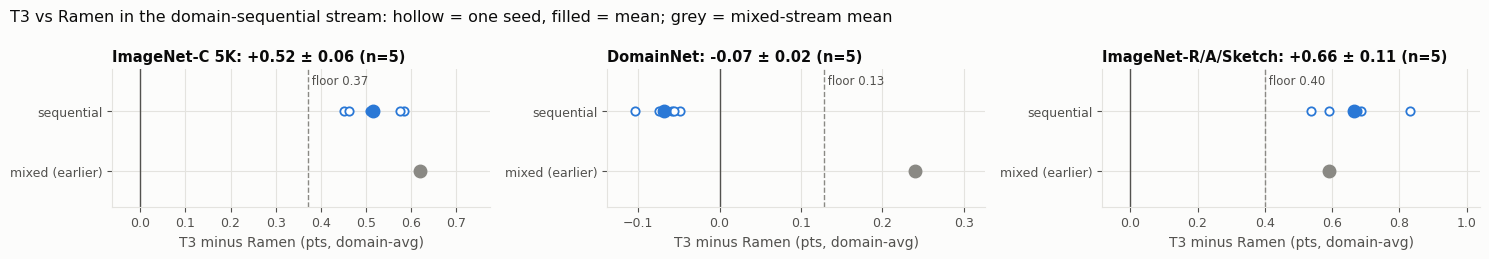

In [9]:
fig = sa.plot_primary(s)

In [10]:
show = s.copy(); show['dataset'] = show.dataset.map(stack.LABEL)
show.set_index(['dataset', 'comparison']).astype({'gain mean': float, 'gain std': float, 'gain min': float, 'images': float}).round(2)

seeds  gain mean  gain std  gain min  floor (seq.) above floor CI > 0   images
dataset             comparison                                                                                                
ImageNet-C 5K       T3 - Ramen                      5       0.52      0.06      0.45          0.37         5/5    5/5    387.2
                    Ramen - NoAdapt                 5       5.89      0.07      5.81          0.37         5/5    5/5   4416.0
                    T3 - NoAdapt                    5       6.40      0.07      6.33          0.37         5/5    5/5   4803.2
                    Ramen-reset - NoAdapt           5       6.71      0.10      6.56          0.37         5/5    5/5   5030.6
                    Ramen - Ramen-reset             5      -0.82      0.05     -0.90          0.37         0/5    0/5   -614.6
                    Ramen (mixed) - NoAdapt         5       5.74      0.10      5.62          0.37         5/5    5/5   4302.2
                    T3 (mixed) - Ramen (mixed)      5       0.62      0.11      0.51          0.37         5/5    5/5    465.6
                    T3-fp32 - Ramen-fp32            1       0.58       NaN      0.58          0.37         1/1    1/1    436.0
                    Ramen-fp32 - Ramen              1      -0.00       NaN     -0.00          0.37         0/1    0/1     -2.0
                    Ramen-fp32 - NoAdapt            1       5.87       NaN      5.87          0.37         1/1    1/1   4406.0
                    T3-fp32 - T3                    1      -0.01       NaN     -0.01          0.37         0/1    0/1     -4.0
DomainNet           T3 - Ramen                      5      -0.07      0.02     -0.10          0.13         0/5    0/5   -789.0
                    Ramen - NoAdapt                 5       1.32      0.03      1.28          0.13         5/5    5/5   8724.0
                    T3 - NoAdapt                    5       1.25      0.02      1.23          0.13         5/5    5/5   7935.0
                    Ramen-reset - NoAdapt           5       1.59      0.02      1.57          0.13         5/5    5/5  10955.8
                    Ramen - Ramen-reset             5      -0.27      0.02     -0.30          0.13         0/5    0/5  -2231.8
                    Ramen (mixed) - NoAdapt         5       1.44      0.02      1.42          0.13         5/5    5/5  10300.6
                    T3 (mixed) - Ramen (mixed)      5       0.24      0.01      0.22          0.13         5/5    5/5   1043.2
                    T3-fp32 - Ramen-fp32            5      -0.12      0.01     -0.13          0.13         0/5    0/5   -750.2
                    Ramen-fp32 - Ramen              5       0.22      0.01      0.21          0.13         5/5    5/5   1962.0
                    Ramen-fp32 - NoAdapt            5       1.54      0.02      1.53          0.13         5/5    5/5  10686.0
                    T3-fp32 - T3                    5       0.17      0.03      0.14          0.13         5/5    5/5   2000.8
ImageNet-R/A/Sketch T3 - Ramen                      5       0.66      0.11      0.54          0.40         5/5    5/5    350.2
                    Ramen - NoAdapt                 5       1.63      0.07      1.52          0.40         5/5    5/5   1504.6
                    T3 - NoAdapt                    5       2.29      0.10      2.21          0.40         5/5    5/5   1854.8
                    Ramen-reset - NoAdapt           5       1.79      0.11      1.68          0.40         5/5    5/5   1555.6
                    Ramen - Ramen-reset             5      -0.16      0.06     -0.24          0.40         0/5    0/5    -51.0
                    Ramen (mixed) - NoAdapt         5       1.48      0.09      1.33          0.40         5/5    5/5   1423.0
                    T3 (mixed) - Ramen (mixed)      5       0.59      0.04      0.56          0.40         5/5    5/5    300.6
                    T3-fp32 - Ramen-fp32            1       0.58       NaN      0.58          0.40         1/1 

## 5. What the order does to Ramen

Domain-averaged accuracy (mean over seeds). Same images in every column.

In [11]:
a = acc.groupby(['dataset', 'run']).acc.mean().unstack()[['NoAdapt', 'Ramen (mixed)', 'Ramen', 'Ramen-reset', 'T3 (mixed)', 'T3']]
a.columns = ['NoAdapt', 'Ramen mixed', 'Ramen sequential', 'Ramen-reset (seq.)', 'T3 mixed', 'T3 sequential']
a['Ramen gain: mixed'] = a['Ramen mixed'] - a.NoAdapt
a['Ramen gain: sequential'] = a['Ramen sequential'] - a.NoAdapt
a['Ramen gain: reset'] = a['Ramen-reset (seq.)'] - a.NoAdapt
a.index = a.index.map(stack.LABEL); a.round(2)

,NoAdapt,Ramen mixed,Ramen sequential,Ramen-reset (seq.),T3 mixed,T3 sequential,Ramen gain: mixed,Ramen gain: sequential,Ramen gain: reset
dataset,,,,,,,,,
DomainNet,55.37,56.81,56.69,56.96,57.06,56.62,1.44,1.32,1.59
ImageNet-C 5K,27.29,33.03,33.18,34.00,33.65,33.69,5.74,5.89,6.71
ImageNet-R/A/Sketch,46.36,47.84,47.99,48.15,48.44,48.65,1.48,1.63,1.79


## 6. Adaptation lag after a domain switch

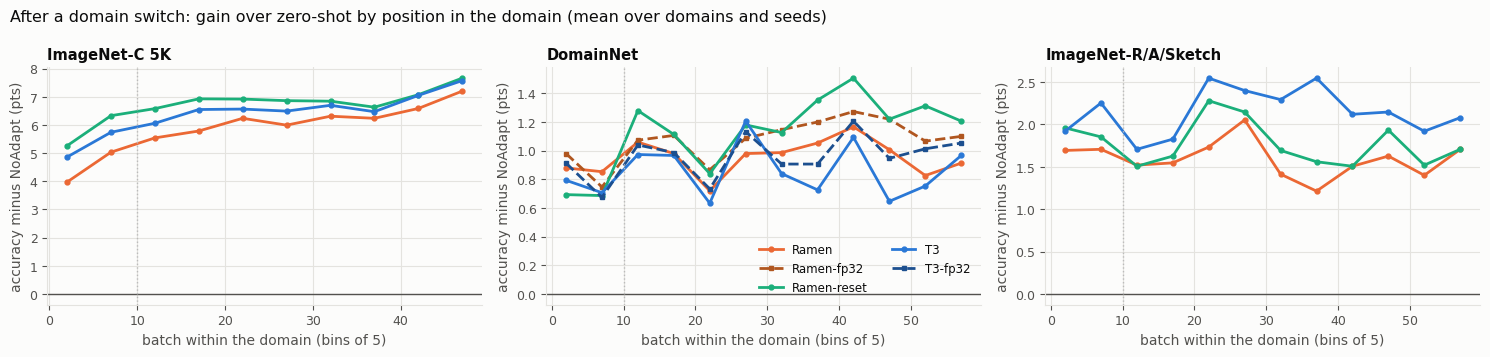

In [12]:
fig = sa.plot_lag(lag)

In [13]:
t = sa.lag_table(lag); t.index = t.index.set_levels(t.index.levels[0].map(stack.LABEL), level=0); t.round(2)  # pts vs NoAdapt

first 10 batches  batches 10+
dataset             run                                       
DomainNet           Ramen                    0.87         1.47
                    Ramen-fp32               0.86         1.80
                    Ramen-reset              0.69         1.85
                    T3                       0.75         1.34
                    T3-fp32                  0.79         1.68
ImageNet-C 5K       Ramen                    4.50         6.23
                    Ramen-fp32               4.64         6.18
                    Ramen-reset              5.79         6.94
                    T3                       5.30         6.68
                    T3-fp32                  5.59         6.67
ImageNet-R/A/Sketch Ramen                    1.70         1.70
                    Ramen-fp32               1.93         1.70
                    Ramen-reset              1.91         1.75
                    T3                       2.09         2.10
                    T3-fp32                  1.63         2.06

### 6b. What the memory holds: fp16 vs fp32 priorities (amendment; descriptive)

Ramen's arrival-counter priorities are fp16. Every insert after sample 65,520 gets priority inf, and a full queue stops updating once all its slots are inf. Below, the whole memory's domain composition at the end of each domain, replayed offline (exact, validated in section 3) from the filing classes logged by the sequential T3 run, seed 0. Also shown: the share of each domain's images that entered the memory.

In [14]:
mc = pd.concat([sa.memory_composition(ds, 0) for ds in sa.DATASETS])
mc.assign(dataset=mc.dataset.map(stack.LABEL)).set_index(['dataset', 'priorities', 'after domain']).drop(columns='seed').round(1).dropna(axis=1, how='all')

% memory from gaussian_noise  % memory from shot_noise  % memory from impulse_noise  % memory from defocus_blur  % memory from glass_blur  % memory from motion_blur  \
dataset             priorities after domain                                                                                                                                                                              
ImageNet-C 5K       fp16       gaussian_noise                            100.0                       0.0                          0.0                         0.0                       0.0                        0.0   
                               shot_noise                                 45.7                      54.3                          0.0                         0.0                       0.0                        0.0   
                               impulse_noise                              29.0                      33.1                         37.9                         0.0                       0.0                        0.0   
                               defocus_blur                               19.2                      22.3                         25.5                        33.0                       0.0                        0.0   
                               glass_blur                                 14.0                      16.6                         18.8                        25.5                      25.1                        0.0   
                               motion_blur                                10.6                      12.9                         14.7                        20.3                      20.2                       21.3   
                               zoom_blur                                   8.4                      10.2                         12.0                        16.7                      16.7                       17.8   
                               snow                                        7.0                       8.6                          9.9                        14.2                      14.1                       15.3   
                               frost                                       5.8                       7.3                          8.4                        12.4                      11.8                       13.6   
                               fog                                         4.9                       6.2                          7.0                        10.8                      10.0                       12.0   
                               brightness                                  4.1                       5.2                          5.9                         9.5                       8.7                       10.6   
                               contrast                                    3.6                       4.6                          5.2                         8.4                       7.7                        9.5   
                               elastic_transform                           3.2                       4.0                          4.6                         7.6                       6.5                        8.6   
                               pixelate                                    2.7                       3.5                          3.9                         6.6                       5.6                        7.6   
                               jpeg_compression                            2.3                       2.9                          3.3                         5.6                       4.9                        6.7   
                    fp32       gaussian_noise                            100.0                       0.0                          0.0                         0.0                       0.0                        0.0   
                               shot_noise                                 45.7                      54.3                      

### 6c. fp32 priorities (amendment)

T3-fp32 − Ramen-fp32 uses the same floor and rule as H1 (DomainNet seeds 0–4; ImageNet-C and R/A/Sketch seed 0 only, as a screen). Ramen-fp32 − Ramen shows what the frozen memory costs or gains.

In [15]:
f = s[s.comparison.isin(['T3-fp32 - Ramen-fp32', 'Ramen-fp32 - Ramen', 'T3-fp32 - T3', 'Ramen-fp32 - NoAdapt', 'Ramen - NoAdapt', 'T3 - Ramen'])]
f.assign(dataset=f.dataset.map(stack.LABEL)).set_index(['dataset', 'comparison'])[['seeds', 'gain mean', 'gain std', 'gain min', 'floor (seq.)', 'above floor', 'CI > 0', 'images']].astype(
    {'gain mean': float, 'gain std': float, 'gain min': float, 'images': float}).round(2)

seeds  gain mean  gain std  gain min  floor (seq.) above floor CI > 0   images
dataset             comparison                                                                                          
ImageNet-C 5K       T3 - Ramen                5       0.52      0.06      0.45          0.37         5/5    5/5    387.2
                    Ramen - NoAdapt           5       5.89      0.07      5.81          0.37         5/5    5/5   4416.0
                    T3-fp32 - Ramen-fp32      1       0.58       NaN      0.58          0.37         1/1    1/1    436.0
                    Ramen-fp32 - Ramen        1      -0.00       NaN     -0.00          0.37         0/1    0/1     -2.0
                    Ramen-fp32 - NoAdapt      1       5.87       NaN      5.87          0.37         1/1    1/1   4406.0
                    T3-fp32 - T3              1      -0.01       NaN     -0.01          0.37         0/1    0/1     -4.0
DomainNet           T3 - Ramen                5      -0.07      0.02     -0.10          0.13         0/5    0/5   -789.0
                    Ramen - NoAdapt           5       1.32      0.03      1.28          0.13         5/5    5/5   8724.0
                    T3-fp32 - Ramen-fp32      5      -0.12      0.01     -0.13          0.13         0/5    0/5   -750.2
                    Ramen-fp32 - Ramen        5       0.22      0.01      0.21          0.13         5/5    5/5   1962.0
                    Ramen-fp32 - NoAdapt      5       1.54      0.02      1.53          0.13         5/5    5/5  10686.0
                    T3-fp32 - T3              5       0.17      0.03      0.14          0.13         5/5    5/5   2000.8
ImageNet-R/A/Sketch T3 - Ramen                5       0.66      0.11      0.54          0.40         5/5    5/5    350.2
                    Ramen - NoAdapt           5       1.63      0.07      1.52          0.40         5/5    5/5   1504.6
                    T3-fp32 - Ramen-fp32      1       0.58       NaN      0.58          0.40         1/1    1/1    305.0
                    Ramen-fp32 - Ramen        1       0.00       NaN      0.00          0.40         0/1    0/1      3.0
                    Ramen-fp32 - NoAdapt      1       1.63       NaN      1.63          0.40         1/1    1/1   1506.0
                    T3-fp32 - T3              1      -0.01       NaN     -0.01          0.40         0/1    0/1     -9.0

## 7. Per domain

Accuracy minus NoAdapt per domain (pts, mean over seeds), domains in stream order. The first domain starts from an empty memory in every stream run.

In [16]:
for ds in sa.DATASETS:
    p = pdm[pdm.dataset == ds]
    order = list(pd.read_pickle(sa.path(ds, 0, 'sequential', 'Ramen')).domain.cat.categories)
    cols = [c for c in ['Ramen (mixed)', 'Ramen', 'Ramen-reset', 'T3', 'Ramen-fp32', 'T3-fp32'] if c in p and p[c].notna().all()]
    m = p.groupby('domain')[['NoAdapt'] + cols].mean().loc[order]
    out = m[cols].sub(m.NoAdapt, axis=0)
    out.columns = [{'Ramen (mixed)': 'Ramen mixed', 'Ramen': 'Ramen seq.', 'T3': 'T3 seq.'}.get(c, c) for c in cols]
    out['T3 - Ramen (seq.)'] = out['T3 seq.'] - out['Ramen seq.']
    print(stack.LABEL[ds]); display(out.round(2))

ImageNet-C 5K


,Ramen mixed,Ramen seq.,Ramen-reset,T3 seq.,T3 - Ramen (seq.)
domain,,,,,
gaussian_noise,6.81,7.18,7.18,8.27,1.09
shot_noise,5.97,6.30,5.98,8.09,1.79
impulse_noise,8.33,8.14,8.58,9.56,1.42
defocus_blur,2.64,2.94,2.80,3.50,0.56
glass_blur,7.16,7.07,8.84,7.48,0.41
motion_blur,5.94,6.59,6.02,6.90,0.31
zoom_blur,5.20,5.59,6.49,6.08,0.49
snow,3.12,2.61,3.37,3.69,1.08
frost,2.28,2.64,4.73,3.05,0.41


DomainNet


,Ramen mixed,Ramen seq.,Ramen-reset,T3 seq.,Ramen-fp32,T3-fp32,T3 - Ramen (seq.)
domain,,,,,,,
clipart,1.13,1.23,1.23,1.16,1.23,1.16,-0.07
infograph,1.02,1.12,1.13,1.07,1.02,0.90,-0.05
painting,1.07,1.27,1.27,1.36,1.19,1.02,0.09
quickdraw,4.32,3.30,4.31,2.95,4.27,4.12,-0.35
real,0.15,0.15,0.21,-0.01,0.17,0.05,-0.17
sketch,0.97,0.85,1.41,1.00,1.39,1.32,0.15


ImageNet-R/A/Sketch


,Ramen mixed,Ramen seq.,Ramen-reset,T3 seq.,T3 - Ramen (seq.)
domain,,,,,
rendition,2.40,2.68,2.68,2.76,0.08
adversarial,0.79,0.97,1.42,2.46,1.49
sketch,1.26,1.24,1.27,1.66,0.42


## 8. Interpretation

**H1 fails on DomainNet.** T3's gain over Ramen survives the sequential stream on two of three datasets:
- ImageNet-C **+0.52 ± 0.06** (floor 0.37, 5/5 above; mixed +0.62).
- ImageNet-R/A/Sketch **+0.66 ± 0.11** (floor 0.40, 5/5; mixed +0.59).
- DomainNet **−0.07 ± 0.02** (floor 0.13, 0/5 above, every per-seed CI below or across zero; mixed +0.24).
- With fp32 priorities (the amendment) DomainNet is also negative, **−0.12 ± 0.01** (0/5). So the DomainNet failure is not caused by the fp16 freeze. Under the pre-registered rule, T3 is **not** confirmed as a general improvement for domain-sequential streams.

**Where T3 loses on DomainNet.** With fp32, T3 − Ramen is negative in all six domains (−0.06 to −0.17), including clipart, the first domain, where the memory holds only clipart. In the mixed stream it was positive in five of six (+0.16 to +0.52). One reading, which is untested: T3 helps when the memory mixes domains (mixed streams; ImageNet-C and R/A/Sketch, where the sequential memory stays mixed, see below) and does nothing or hurts when the memory is one domain. The direct test is T3 with a reset at each domain start, vs Ramen-reset. That is **post-hoc** and was not run.

**The fp16 priority bug matters in sequential streams** (amendment; replayed memory composition, seed 0):
- DomainNet: the fp16 memory freezes during painting. Only 6.7% of quickdraw and 6.8% of real images ever enter it, and 0.3% of sketch; at the end it is 77% infograph + painting.
- Fixing it is worth **+0.22 ± 0.01** for Ramen (5/5 above the floor) and +0.17 for T3; quickdraw alone goes from +3.30 to +4.27 over NoAdapt.
- ImageNet-C and R/A/Sketch: no effect (seed 0: −0.00 and +0.00), as predicted, because their streams barely pass the 65,520 point.
- Practical consequence: any non-stationary-stream claim about Ramen should use fp32 priorities, and published Ramen numbers on long sequential streams are partly measuring this bug.

**Carrying memory across domains hurts Ramen everywhere.** Ramen-reset, which knows the boundaries, beats sequential Ramen:
- ImageNet-C **+0.82 ± 0.05**: 0/5 seeds favour sequential.
- DomainNet +0.27, or about +0.04 against fp32 Ramen (56.96 vs 56.92).
- R/A/Sketch +0.16, below the floor.

The ImageNet-C case is a capacity effect, not a bug. Its 75 slots × 1,000 classes exceed the 5,000 images per corruption, so nothing is evicted and old corruptions pile up. At the end of corruption n only about 1/n of the memory is the current one (9.5% at jpeg_compression). The largest per-domain losses from not resetting are on late corruptions: elastic_transform −3.5, frost −2.1, glass_blur −1.8, jpeg_compression −1.6.

**Order effect on Ramen (secondary 1).** Sequential vs mixed (each minus NoAdapt): ImageNet-C +5.89 vs +5.74, R/A/Sketch +1.63 vs +1.48, DomainNet +1.32 vs +1.44 (fp32 +1.54). Apart from the fp16 freeze, Ramen does about as well, or slightly better, when domains arrive in order.

**Adaptation lag (secondary 3).** In the first 10 batches of a domain the gain over NoAdapt is lower than later: ImageNet-C Ramen +4.50 vs +6.23, DomainNet +0.87 vs +1.47. Ramen-reset starts from an empty memory, yet on ImageNet-C it is *better* early (+5.79). The stale memory costs more than an empty one. On DomainNet it is slightly worse early (+0.69) and better later (+1.85). R/A/Sketch shows no lag.

**Caveats.** One domain order per dataset. The fp32 screens on ImageNet-C and R/A/Sketch are seed 0 only. The "T3 needs a mixed memory" reading is a hypothesis from per-domain patterns.

**What this changes.**
1. T3 is confirmed on three mixed streams and two of three sequential ones; it is not a universal improvement. DomainNet, the largest stream and the one with the largest memory (300 per class, top-10, β = 5), is where it fails.
2. Two findings about Ramen that matter for any continual-TTA claim: the fp16 priority freeze, and memory staleness across domains when capacity exceeds the per-domain volume (ImageNet-C −0.82). A boundary-free fix for staleness (e.g. evicting by age, or a capacity matched to the stream rate) is a candidate method change. Its oracle ceiling, from Ramen-reset, is +0.82 on ImageNet-C and +0.27 on DomainNet.


## 9. Glossary

| Term | Meaning |
|---|---|
| Ramen | CLIP zero-shot + per-class memory of (feature, entropy gradient); one signSGD step per batch from retrieved entries, predict, reset the weights (the memory persists) |
| T3 | Ramen with a zero-shot-weighted active set: each class queue's vote weighted by the query's zero-shot probability at temperature 3 |
| mixed stream | all domains shuffled into one stream |
| sequential stream | domains one after another, each shuffled within itself; the method is never told where a domain starts |
| Ramen-reset | Ramen whose memory is emptied at every domain start (needs the boundaries; a reference, not a fair competitor) |
| adaptation lag | how long after a domain switch the gain over zero-shot takes to recover |
| fp16 / fp32 priorities | Ramen evicts the lowest arrival counter from a full queue; in fp16 the counter becomes inf after 65,520 samples and full queues stop changing (Ramen as published); fp32 keeps them updating |
| noise floor | 2 × (max − min) of sequential Ramen's domain-averaged accuracy over seeds 0–4 |
| domain-averaged accuracy | mean of per-domain accuracies |
| fixed / broken | images the reference gets wrong and the variant right / and the reverse |
| cluster bootstrap CI | 95% interval from resampling images (Poisson weights; base image on ImageNet-C), per seed |